# WASP-39 b with NIRCam/F322W2: 1/f noise and a default that a transit overturned

The same transit programme as the [PRISM tutorial](wasp39b_prism.ipynb)
(ERS 1366) observed WASP-39 b with the NIRCam long-wave grism and the F322W2
filter, 2.4-4.0 µm (Ahrer et al. 2023, Nature 614, 653). NIRCam grism data
have a noise problem of their own: correlated 1/f read noise that the
standard pipeline does not fully remove. This tutorial is about that noise:

* why it is worse on NIRCam than on NIRSpec, and how jstark removes it at
  the group level (a read-time model with a common mode across the four
  amplifiers);
* how the extraction weights the columns for summed light curves;
* and a lesson in testing: a refinement that lowered the scatter on every
  data set without a transit (measuring the 1/f offsets on the faint wings of
  the trace) turned out to dilute the transit depths by 70 ppm. It is no
  longer the default.

The PRISM tutorial explains the stages that work the same way (saturation,
cosmic rays, the PSF model); here we concentrate on what differs.

**Contents**

1. The data and the 1/f problem
2. Stage 1 on segment 1, and three ways to treat the 1/f noise
3. Cleaning and extraction (segment 1)
4. The full exposure: what the transit showed
5. White-light fit per amplifier
6. Transmission spectrum
7. Summary

## The data

| | |
| --- | --- |
| Programme | JWST ERS 1366, observation 2 (22 July 2022) |
| Mode | NIRCam LW grism time series, GRISMR + F322W2, SUBGRISM256, 4 outputs |
| Read-out | SHALLOW4, 12 groups (6.7 s each), 80 s per integration |
| Integrations | 366, in 4 segments |
| Files | `jw01366002001_04103_00001-seg00[1-4]_nrcalong_uncal.fits` (4.7 GB) |

```python
from astroquery.mast import Observations

obs = Observations.query_criteria(obs_collection='JWST', proposal_id='1366',
                                  instrument_name='NIRCAM/GRISM')
prods = Observations.filter_products(Observations.get_product_list(obs),
                                     productSubGroupDescription='UNCAL')
keep = [f.startswith('jw01366002001_04103') and f.endswith('_nrcalong_uncal.fits')
        for f in prods['productFilename']]
Observations.download_products(prods[keep], download_dir=DATA, flat=True)
```

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table

from jstark.reduction import Stage1, Stage2, ExposureCleaner
from jstark.reduction import diagnostics as rdiag
from jstark.extraction import SpectralExtractor, Spectra
from jstark.extraction import diagnostics as xdiag
from jstark.extraction.metrics import p2p_sigma
from jstark.fitting import LightCurves, BroadbandFit, SpectroscopicFit, Spectrum

DATA = '/Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRC_LW'      # the uncal files
TUT = os.path.join(DATA, 'tutorial')                         # segment 1 (this notebook)
NEW = os.path.join(DATA, 'reduction_variants', 'readout_nowing')   # full exposure, current defaults
OLD = os.path.join(DATA, 'reduction')                        # full exposure, previous default (wing pixels)
OFFICIAL = os.path.join(DATA, 'reduction_official')          # official calwebb_detector1 + jstark extraction
ROOT = 'jw01366002001_04103_00001_nrcalong'
RUN_FULL = False

from jstark.plotting import use_style
use_style()                                         # the style of the jstark diagnostic plots
%config InlineBackend.figure_formats = ['retina']
os.makedirs(TUT, exist_ok=True)

## 1. Why 1/f noise is worse on NIRCam

The detector is read by four amplifiers, each covering 512 columns, and each
amplifier reads its pixels row after row along the fast direction (10 µs per
pixel). Slow drifts of the electronics (1/f noise) add an offset that is
nearly constant along a row of one amplifier and changes from row to row.

On NIRSpec the spectrum is dispersed *across* those stripes, so one stripe
affects one wavelength and can be measured from the empty pixels in the same
column. The NIRCam grism disperses *along* the rows: one stripe adds the same
offset to hundreds of wavelengths at once, so it does not average out in a
spectral bin or the white light. And the trace fills the rows it crosses:
in those rows two or three of the four amplifiers have no empty pixels to
measure the offset from (Schlawin et al. 2020, arXiv:2010.03564).

Measurements on other NIRCam data sets (HD 207496, F444W and F322W2) showed:

* 96% of the row-to-row 1/f is **common to all four amplifiers**
  (correlation 0.92-0.97 between amplifiers), about 36 DN rms per row;
* the amplifier-specific remainder (~6 DN rms) decorrelates within ~5 rows,
  so it cannot be interpolated across the ~28 rows of the trace;
* the excess noise is additive (it grows with the aperture), not jitter;
* every fourth integration is ~55 DN lower (fast-frame resets; Schlawin et
  al. 2023), the "phase-of-4" pattern, removed later with a regressor.

## 2. Stage 1

The NIRCam recipe uses the side reference pixels in `refpix` (with separate
odd and even columns) and then `group_bkg` with `method='readout'`: for
every group, the background pixels give the row offsets of each amplifier,
and these are modelled as a smooth function of the read time plus a common
mode shared by all amplifiers read at the same moment. Rows where an
amplifier has no background pixels get the common mode and the smooth
model; rows that are measured directly keep their measurement.

In [2]:
s1 = Stage1(DATA, outdir=TUT, exposure='04103')
s1.set('ramp_fit', maximum_cores='4')
s1.show()

jstark Stage1: NIRCam/F322W2 | exposure jw01366002001_04103_00001_nrcalong | 4 segment(s) | output -> /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRC_LW/tutorial
Recipe for NIRCam/F322W2:
   0. [run ] jwst   group_scale          
   1. [run ] jwst   dq_init              
   2. [run ] jwst   saturation           {'n_pix_grow_sat': 1}
   3. [run ] jstark consistent_saturation {'min_frac': 0.01, 'scope': 'exposure'}
   4. [run ] jwst   superbias            
   5. [SKIP] jstark custom_bias          {'method': 'scaled', 'mode': 'smooth'}
   6. [run ] jwst   refpix               {'odd_even_columns': True, 'use_side_ref_pixels': True}
   7. [run ] jstark group_bkg            {'method': 'readout', 'axis': 'row', 'readout_order': 1}
   8. [run ] jwst   linearity            
   9. [SKIP] jwst   dark_current         
  10. [SKIP] jwst   charge_migration     
  11. [SKIP] jwst   jump                 {'rejection_threshold': 15.0, 'maximum_cores': 'half'}
  12. [run ] jstark temporal_jump        {'windo

We run segment 1 (92 integrations).

In [3]:
%%time
s1.compute_saturation_map(segments=[0])
rateints = s1.run(segments=[0])
diag = rdiag.load_stage1_diagnostics(rateints[0].replace('_rateints.fits', '_stage1diag.npz'))

  saturation pre-pass: segment 1/4
  saturation map: 3043 pixels saturate (in >= 1% of integrations); first saturated group histogram [137, 154, 144, 320, 200, 335, 281, 248, 483, 176, 304, 261, 521245]
Segment 1/4: jw01366002001_04103_00001-seg001_nrcalong_uncal.fits


    group_scale          done in    0.3 s


    dq_init              done in    0.5 s


    saturation           done in    4.5 s


    consistent_saturation: 3043 pixels, 1624840 saturated-group flags added
    consistent_saturation done in    0.7 s


    superbias            done in    0.5 s


... (3 outputs left out)

    linearity            done in    1.9 s


    temporal_jump: 277098 jumps (flag), median fraction of pixels hit per integration = 0.417%
    temporal_jump        done in   62.4 s


    ramp_fit             done in   17.6 s
    gain_scale           done in    0.2 s


  -> /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRC_LW/tutorial/jw01366002001_04103_00001-seg001_nrcalong_rateints.fits  (181.2 s)
CPU times: user 2min 33s, sys: 23.2 s, total: 2min 56s
Wall time: 3min 14s


amplifier 1: no background pixels in 55 rows
amplifier 2: no background pixels in 60 rows
amplifier 3: no background pixels in 77 rows
amplifier 4: no background pixels in 3 rows


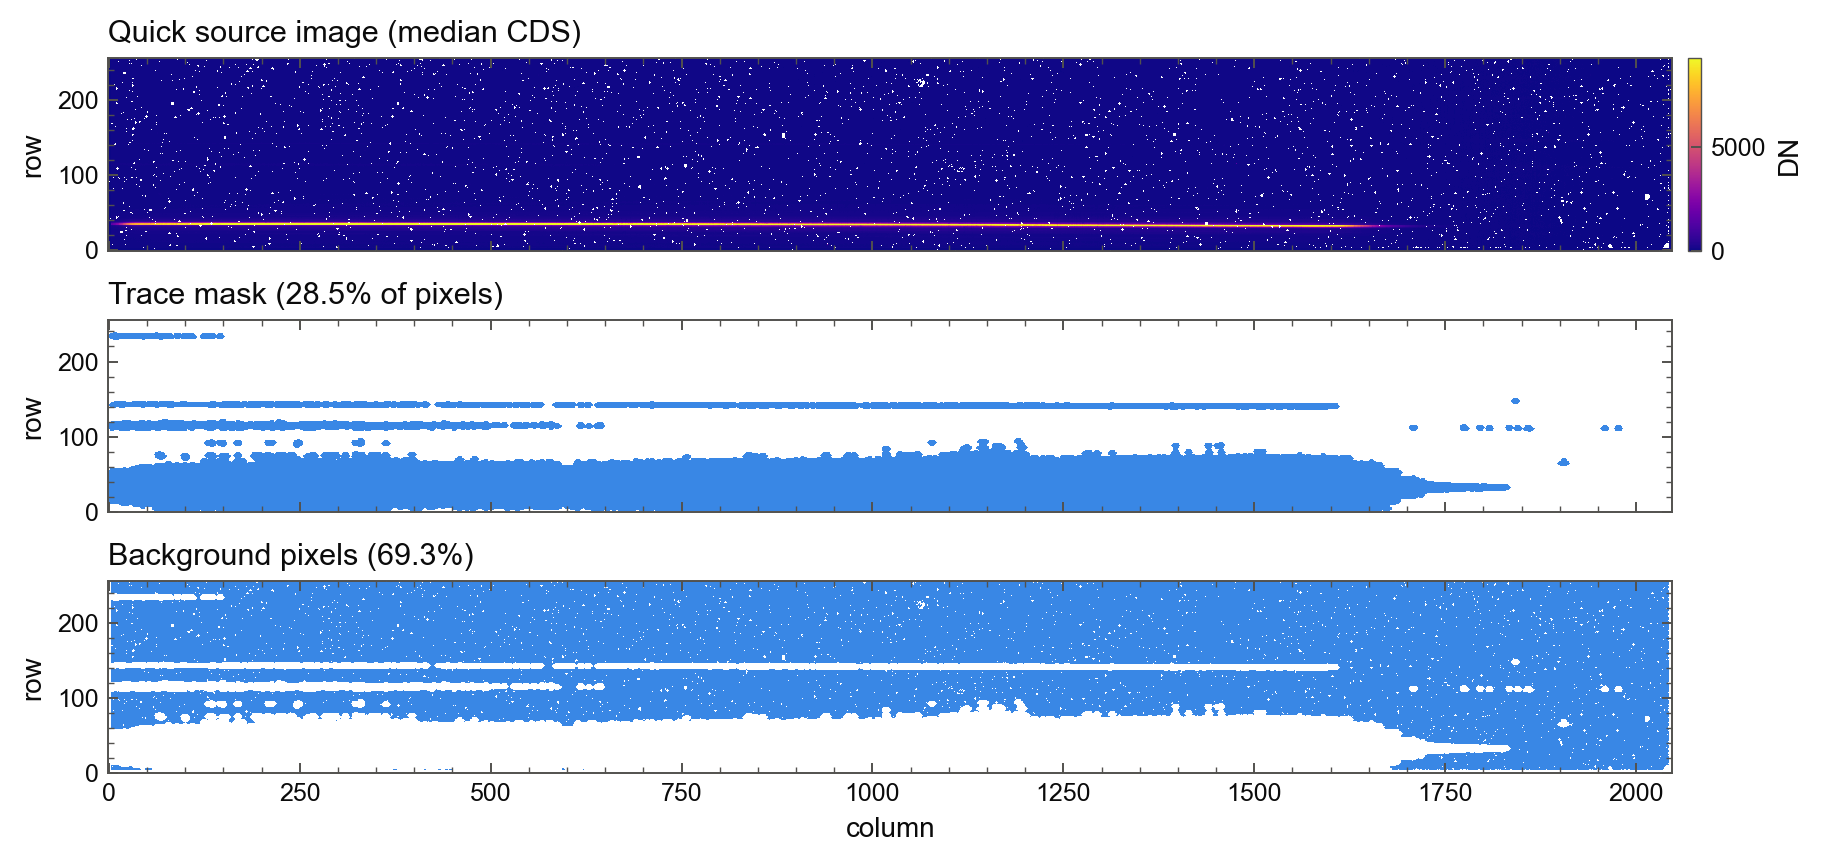

In [4]:
rdiag.plot_masks(s1.signal_image, s1.trace_mask, s1.bkg_mask)
# rows (outside the reference rows) in which an amplifier has no background pixel
science_rows = (s1.trace_mask | s1.bkg_mask).any(axis=1)
for a in range(4):
    cols = slice(512 * a, 512 * (a + 1))
    empty = science_rows & (s1.bkg_mask[:, cols].sum(axis=1) == 0)
    print(f'amplifier {a + 1}: no background pixels in {empty.sum()} rows')

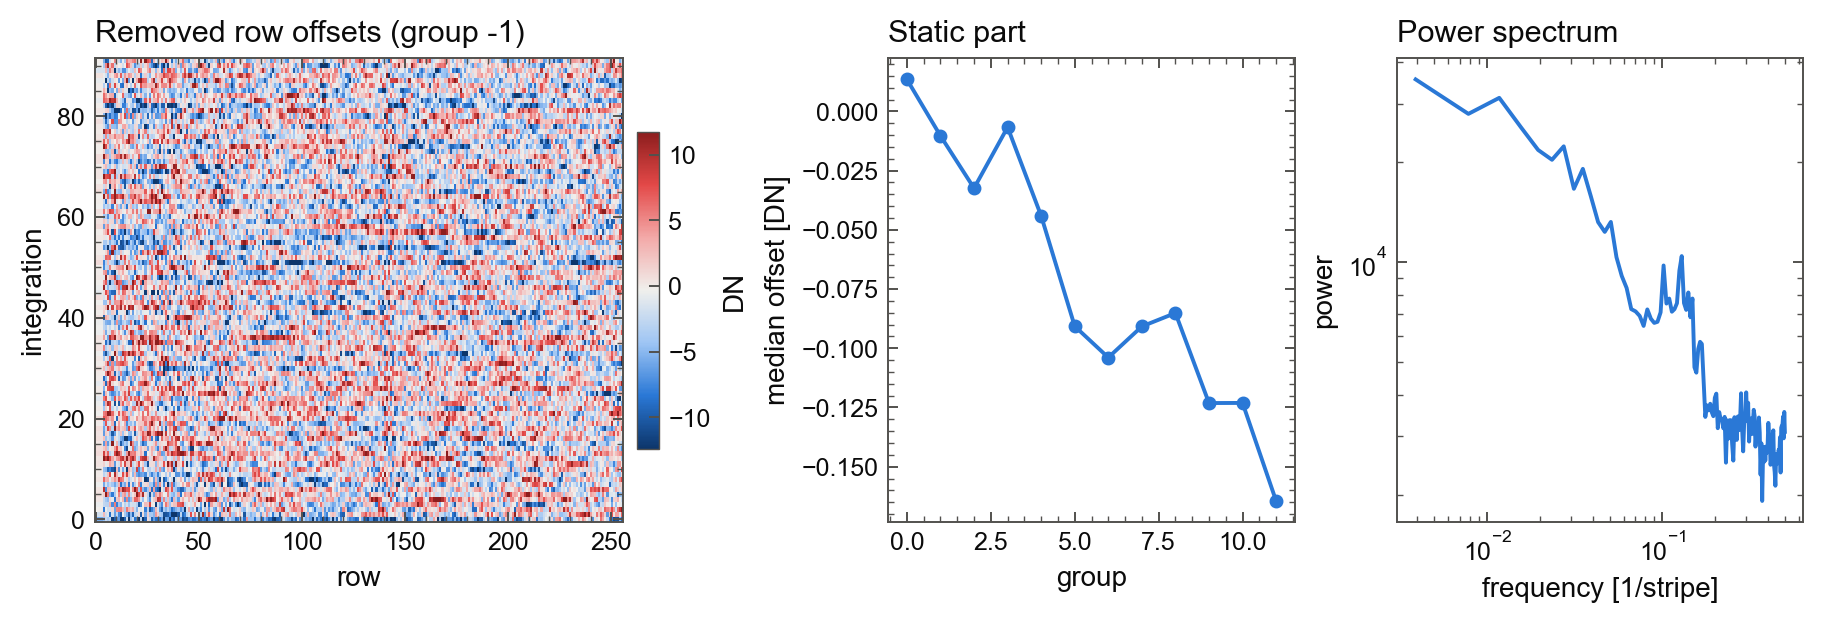

In [5]:
rdiag.plot_group_bkg(diag['group_bkg']['profile'], axis='row');

The left panel shows the row offsets removed from the last group of every
integration, averaged over the four amplifiers: mostly the common mode,
stripes that change from integration to integration.

### 2.1 Why the methods are not compared on one segment

Comparing 1/f treatments needs many integrations. With the 92 integrations
of one segment the point-to-point scatter of the white light is known only
to about ±7%. Running the comparison on segment 1 alone (Stage 1 variants,
then the same cleaning and extraction) even ranked the methods in a
different order than the full exposure does. The methods are therefore
compared on the full exposure (Section 4).

Two settings that can be tried with `s1.set('group_bkg', ...)`:

* `skip=True`: no group-level correction (as in the official pipeline);
* `wing_frac=0.04`: the offsets are also measured on the faint wings of the
  trace (pixels below 4% of the peak signal per group). In difference
  images (each group minus the scaled median frame) the static starlight
  cancels, so wing pixels can stand in for missing background pixels and
  fewer rows are left to the model. On HD 207496 and 55 Cnc (segments
  without a transit, 740-760 integrations) this, together with the
  extraction weights below, lowered the white-light scatter by about 35%,
  and it became the default. Section 4 shows what the full transit said.

## 3. Cleaning and extraction (segment 1)

Stage 2, cleaning and the PSF fit work as for PRISM. The NIRCam default
extraction differs: `method='covariance'` with `cov_scale=500`.

Wavelength map (256, 2048): 2.400-4.391 micron
Saved wavelength map to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRC_LW/tutorial/jw01366002001_04103_00001_nrcalong_wavelength.fits
ExposureCleaner: NIRCam/F322W2 | jw01366002001_04103_00001_nrcalong | 1 segment(s), 92 integrations


  pass 1: segment 1/1 read


compute_global: 17969 bad pixels from DQ, 362 hot/noisy pixels; trace mask 29.2% of pixels


  segment 1/1: 124364 transient flags (1351.8 per integration) -> jw01366002001_04103_00001-seg001_nrcalong_cleaned.fits
Saved exposure info to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRC_LW/tutorial/jw01366002001_04103_00001_nrcalong_cleaninfo.fits
SpectralExtractor: NIRCam/F322W2 | jw01366002001_04103_00001_nrcalong | 1 segment(s), 92 integrations | orders [1]
NIRCam/F322W2 | orders [1]
  columns     columns=None, wavelength_range=None, snr_min=5.0, min_good_frac=0.5, gap=5
  trace       halfwidth=None, nknots=8, clip=3.0, reference=None, ref_order=1
  background  method=median, inner=12.0, outer=None, nsigma=3.0, maxiters=3, poly_order=1, min_pixels=10
  psf         halfwidth=9.0, oversample=2.0, knot_col=20, smooth=cv, clip=6.0, init_ints=200, ints=all, second_pass=False, pixel_correction=True, cv=phase
  extract     method=covariance, aperture=6.0, variance=mean, reject=6.0, reject_iters=3, reject_mode=temporal, fit_background=False, refine_shift=2, joint_iters=3, max_maskfrac=0.9

  order 1: columns 4-1783, 2.404-4.132 um; trace rows 32.28-35.56; centroid rms about the fit 0.012 px


  order 1: first PSF from 92 integrations; residual scale 1.00 sigma; 0.000% of pixels rejected


  order 1: PSF pass 1: 2899568 pixels from 92 integrations, 936 coefficients, smoothing (u, x) = (2e-05, 2e-01), reduced chi2 3.576, rejected 0.000%
  pixel-response map: 31549 pixels, rms 0.0368
fit_psf done in 15 s
  order 1: 6 column(s) with < 2 usable groups in the aperture set to NaN: columns [757, 758, 759, 1437, 1438, 1439] (3.128-3.795 um)


  order 1: row-offset covariance from 90 integrations; rms row offset per amplifier: 0.018, 0, 0, 0.0137


  segment 1/1: 92 integrations; order 1: 0.3 rejected px/int, dy rms 0.6 mpx
extraction done in 18 s
Saved spectra to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRC_LW/tutorial/jw01366002001_04103_00001_nrcalong_spectra.fits


CPU times: user 1min 6s, sys: 26 s, total: 1min 32s
Wall time: 53.9 s


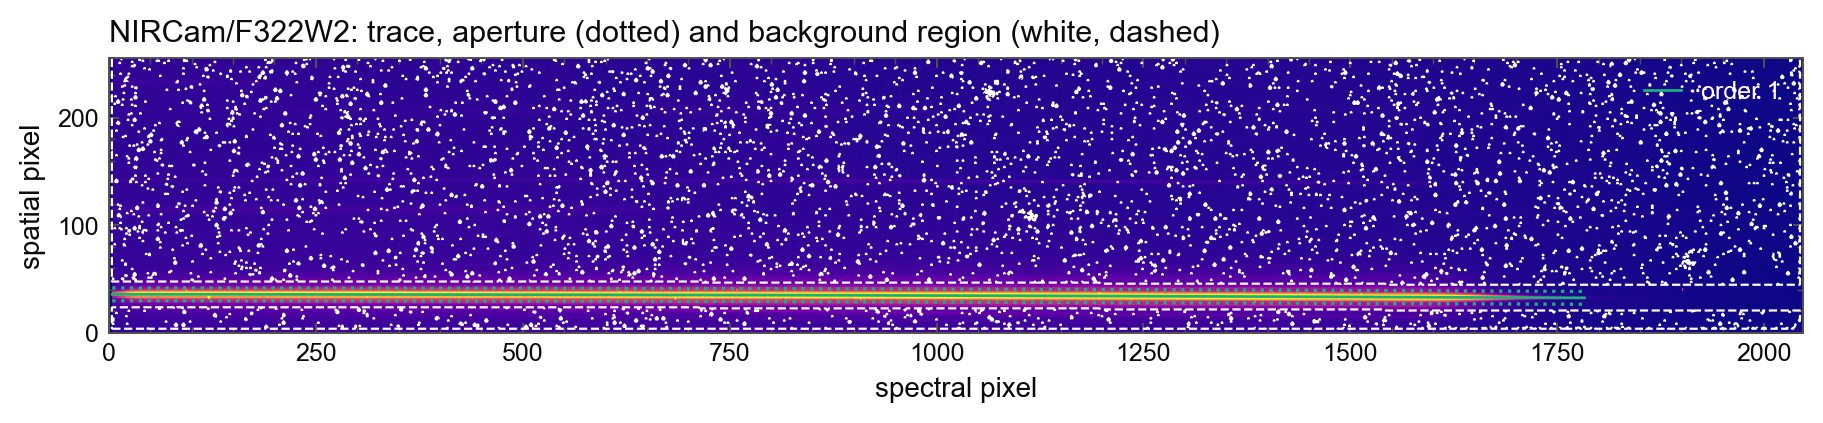

In [6]:
%%time
wfile = Stage2(TUT).run()['wavelength']
info = ExposureCleaner(TUT, wavelength=wfile).run()
ex = SpectralExtractor(info)
ex.show()
ex.find_trace()
ex.fit_psf()
spec1 = ex.run()
xdiag.plot_trace(ex);

<div class="alert alert-info">

**Why covariance weights for summed columns**

A row offset is shared by all ~500 columns of an amplifier. In a column, the
pixel noise $V$ dominates and the 1/f covariance $K$ is negligible, so
weighting columns one by one gains nothing (an extraction with the full
per-column covariance gave the same white light as optimal extraction). But
in a sum of $B$ columns (a spectral bin, the white light) the offsets add up
coherently, as $B^2 K$, while pixel noise adds as $B V$. The weights that
minimise the noise of the sum are $w \propto (V + B K)^{-1} P$: in the faint
wings, where $V$ is mostly read noise, $B K$ dominates and the weight drops;
in the bright core nothing changes. With $B = 500$ (one amplifier) the
white-light scatter fell by about 10% on HD 207496 (F444W 182 → 166 ppm,
F322W2 218 → 196 ppm). The saved variance is that of each column for these
weights.

</div>

## 4. The full exposure: what the transit showed

The full transit was reduced several times, identical except for the
group-level step: the previous default (with wing pixels), the current
default (no wing pixels), and the variants `diff` and `median`. The official
`calwebb_detector1` (CRDS defaults, no 1/f correction) followed by the same
jstark extraction serves as the reference that cannot dilute the transit.
Every reduction took about 40 minutes.

In [7]:
if RUN_FULL:
    s1 = Stage1(DATA, outdir=NEW, exposure='04103')
    s1.set('ramp_fit', maximum_cores='4')
    s1.run(save_variances=False)
    wfile_full = Stage2(NEW).run()['wavelength']
    info_full = ExposureCleaner(NEW, wavelength=wfile_full).run()
    exf = SpectralExtractor(info_full)
    exf.find_trace(); exf.fit_psf(); exf.run(keep_segments=False)

official Stage 1           white-light p2p   266 ppm
previous default (wings)   white-light p2p   203 ppm


current default            white-light p2p   213 ppm


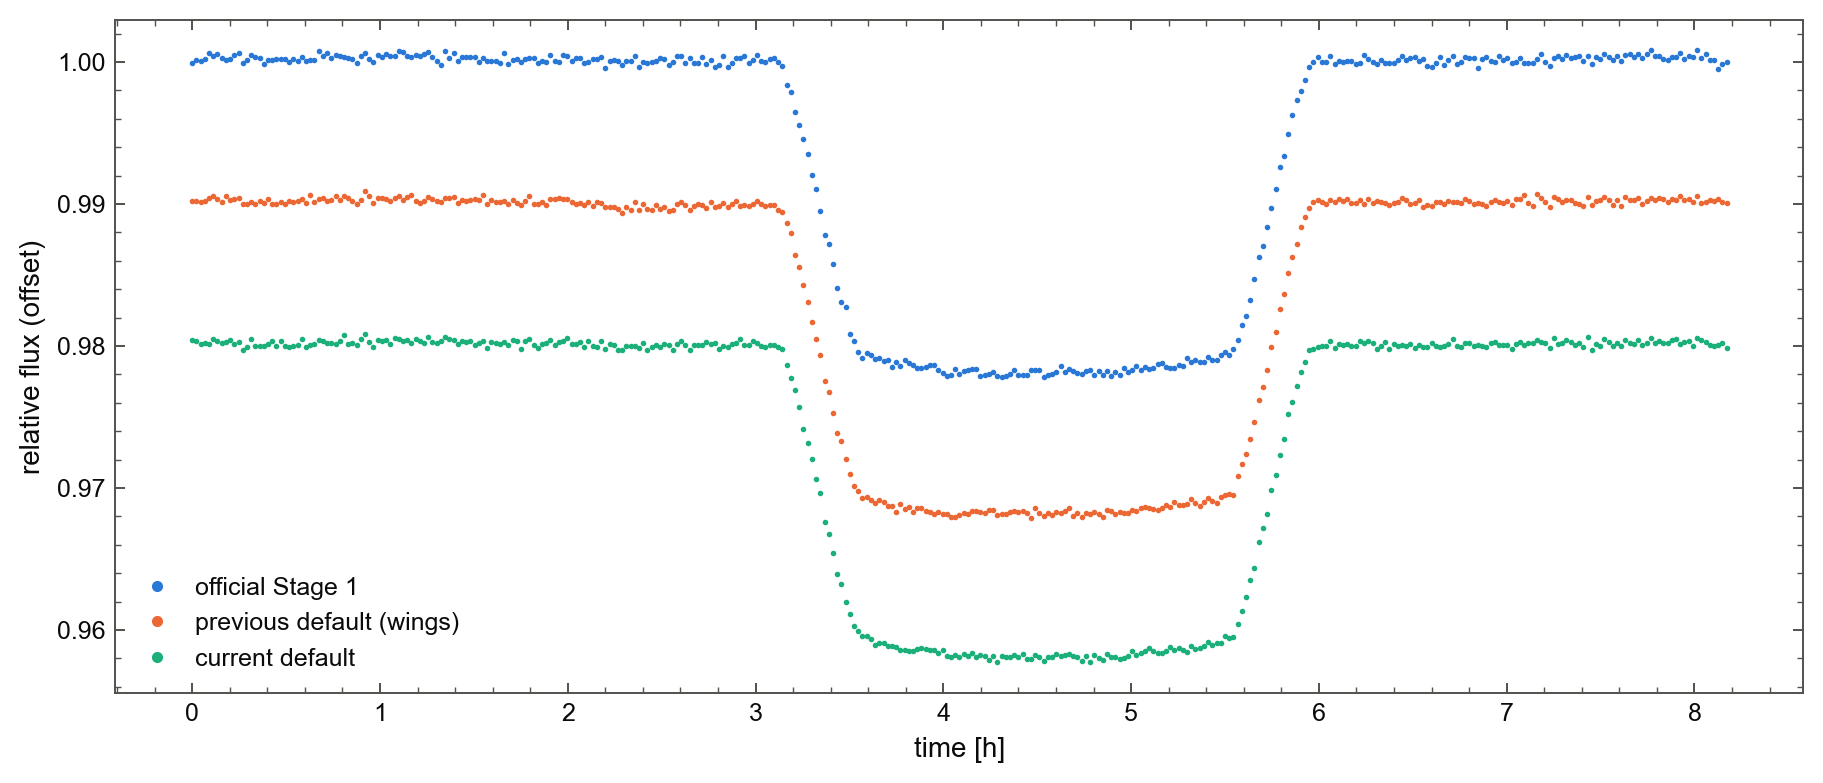

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
for k, (name, d) in enumerate({'official Stage 1': OFFICIAL, 'previous default (wings)': OLD,
                               'current default': NEW}.items()):
    lc = LightCurves.from_spectra(os.path.join(d, f'{ROOT}_spectra.fits')).exclude(ints=[(0, 1)])
    f, _ = lc.white_light()
    trend = np.convolve(f, np.ones(9) / 9, mode='same')
    ph = np.arange(len(f)) % 4
    for p in range(4):
        f = np.where(ph == p, f - np.median((f - trend)[ph == p]), f)
    print(f'{name:26s} white-light p2p {p2p_sigma(f[4:-4]) * 1e6:5.0f} ppm')
    ax.plot((lc.times - lc.times[0]) * 24, f - 0.01 * k, '.', ms=2, label=name)
ax.set_xlabel('time [h]'); ax.set_ylabel('relative flux (offset)')
ax.legend(markerscale=3, loc='lower left');

<div class="alert alert-info">

**What the full transit showed (fitted spectra, R = 100 bins)**

Depth differences against the official Stage 1, in the 49 bins of the ERS
benchmark spectrum (covariance extraction), and the white-light noise
(residuals about a linear trend and a fixed transit):

| `group_bkg` | depth − official (ppm) | white rms / p2p (ppm) | β at 8 / 32 integrations |
| --- | --- | --- | --- |
| none (official) | 0 | 241 / 217 | 1.42 / 2.14 |
| `readout` + `wing_frac=0.04` (previous default) | **−70 ± 9** | 230 / 178 | 1.89 / **3.25** |
| **`readout`, background pixels only (default)** | −14 ± 5 | 201 / 187 | 1.41 / 2.20 |
| `diff` | −25 ± 5 | 190 / 173 | 1.41 / 2.07 |
| `median` | −46 ± 5 | 200 / 190 | 1.30 / 1.80 |

(The scatter printed above is that of the raw white light, transit
included; the table uses the residuals of a fit, hence the lower values.
The ranking is the same.)

The wing pixels gave the lowest point-to-point scatter, as on the data
without a transit, but they **diluted the transit by 70 ppm** and added red
noise. The difference images use the median frame scaled by the white light;
the wings do not transit exactly like the white light, so a transit-shaped
residual is left in them, and the row-offset model subtracts it from whole
rows. On data without a transit nothing like this can show. Every
group-level correction dilutes a little, least the `readout` model on
background pixels only (−14 ppm), which still lowers the noise compared with
no correction.

**Decision:** `readout` on background pixels only is the NIRCam default;
`wing_frac` stays available but is documented as biasing transit and
eclipse depths.

</div>

## 5. White-light fit per amplifier

What remains of the 1/f noise is mostly shared by the columns of one
amplifier. NIRCam spectra record the amplifier of each column, and
`LightCurves.split()` gives one dataset per amplifier. Their white lights
are fitted jointly: one orbit, but each amplifier with its own depth and
limb darkening (the amplifiers cover different wavelengths, 2.42-2.89,
2.89-3.39, 3.39-3.89 and 3.89-4.03 µm, so their depths differ). The systematics
are a linear trend and the phase-of-4 regressor `phase4`. The first
integration is removed.

In [9]:
lc = LightCurves.from_spectra(os.path.join(NEW, f'{ROOT}_spectra.fits'), name='NRC').exclude(ints=[(0, 1)])
amps = lc.split()
print({a: amps[a].flux.shape[1] for a in amps}, '(columns per amplifier)')
white_dir = os.path.join(NEW, 'fits', 'white_amps')
if RUN_FULL:
    pri = {'P_p1': ('fixed', 4.0552941), 't0_p1': ('normal', [2459783.50156, 0.01]),
           'b_p1': ('uniform', [0., 1.]), 'a_p1': ('uniform', [5., 20.]),
           'ecc_p1': ('fixed', 0.), 'omega_p1': ('fixed', 90.)}
    for a in amps:
        pri.update({f'p_p1_{a}': ('uniform', [0.1, 0.2]),
                    f'q1_{a}': ('uniform', [0., 1.]), f'q2_{a}': ('uniform', [0., 1.])})
    fit = BroadbandFit(amps, priors=pri, out_folder=white_dir, linear=['time', 'phase4'])
    fit.fit(nthreads=4)
fit = BroadbandFit.load(white_dir)
summ = fit.summary()
summ[[n.startswith(('t0', 'a_p1', 'b_p1', 'depth')) for n in summ['name']]]

{'A1': 508, 'A2': 512, 'A3': 512, 'A4': 244} (columns per amplifier)


Detected dynamic_dynesty sampler output files --- extracting from /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRC_LW/reduction_variants/readout_nowing/fits/white_amps/_dynesty_DNS_posteriors.pkl


name,median,err_plus,err_minus,kind
str15,float64,float64,float64,str7
t0_p1,2459783.501547714,1.9990839064121246e-05,2.0748935639858246e-05,fitted
b_p1,0.44552456453341677,0.006285798394325859,0.00661509938558863,fitted
a_p1,11.402586683192425,0.03359977182785556,0.032466732687918665,fitted
depth_p1_A1_ppm,21582.948045560865,68.90767587198206,68.1535338362628,derived
depth_p1_A2_ppm,21261.42866332434,61.52910369599704,59.09862647715636,derived
depth_p1_A3_ppm,20963.652491950055,62.8641302718097,62.76362154324306,derived
depth_p1_A4_ppm,20976.70493906783,79.07371820037952,77.80246810567769,derived


In [10]:
fit.diagnostics()

dataset,n,p2p_ppm,err_ppm,sigma_w_ppm,p2p_over_err,p2p_over_total,beta_8,beta_16,beta_32,beta_64,beta_128
str2,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
A1,365,282.0393734152554,185.3079,209.4677353325013,1.5220040452417594,1.0084691894866524,1.1090697285140907,1.2978189433983907,1.6978125955480912,nan,nan
A2,365,236.59419680098543,165.82860000000002,185.67863701362228,1.4267393971907465,0.9503715673265973,1.1970511241061723,1.3113660785122299,1.6201434106891515,nan,nan
A3,365,266.1019342322227,170.9607,219.80393137050234,1.5565093862637591,0.9556115950985373,1.2425544004853515,1.4134782375231967,1.734117396819259,nan,nan
A4,365,420.56735838184653,404.5764,236.88948902742928,1.0395251882755558,0.8970631344983353,1.1372145565947867,1.0260096593517574,1.22473771547666,nan,nan


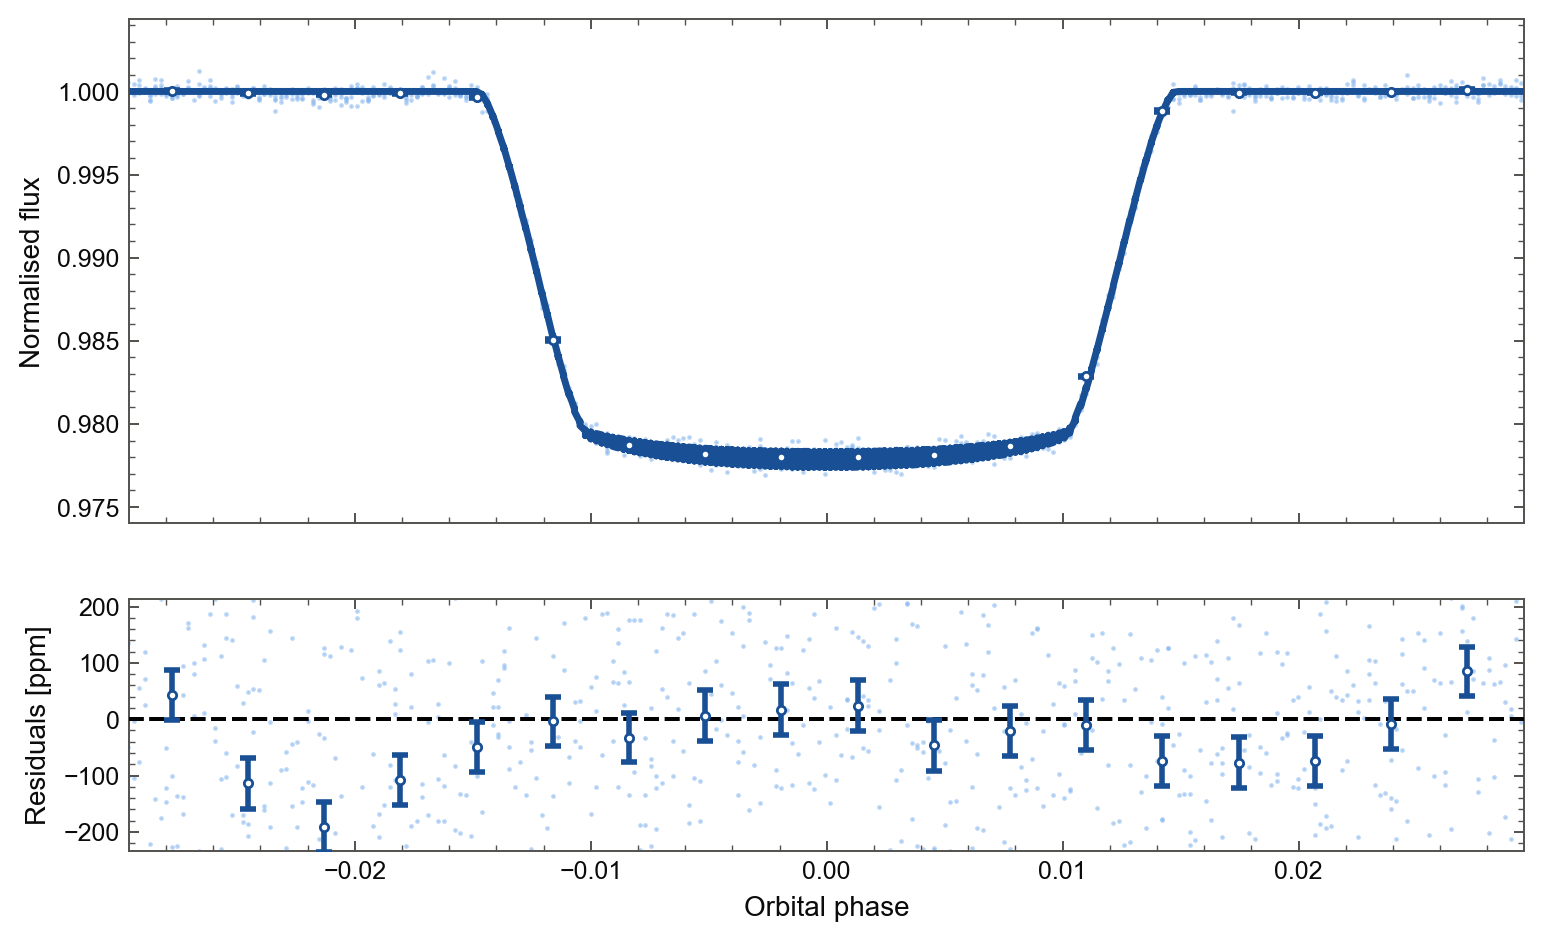

In [11]:
fit.plots().phase_folded_lc();

The orbit ($a/R_* = 11.40 \pm 0.03$, $b = 0.446 \pm 0.007$) agrees with the
ERS benchmark (11.39, 0.450) and with our PRISM fit. With the previous
default it was 11.36 and 0.452: the diluted transit also pulled the orbit.

## 6. Transmission spectrum

The spectrum is fitted in the 49 R = 100 bins of the ERS benchmark, with the
orbit fixed to the joint white-light fit and, per bin, $R_p/R_*$, q1, q2, a
linear trend and `phase4`.

previous default (wings)   median offset to ERS  -108 ppm, rms after it  77 ppm, error ratio 0.99
current default            median offset to ERS   -60 ppm, rms after it  75 ppm, error ratio 0.98


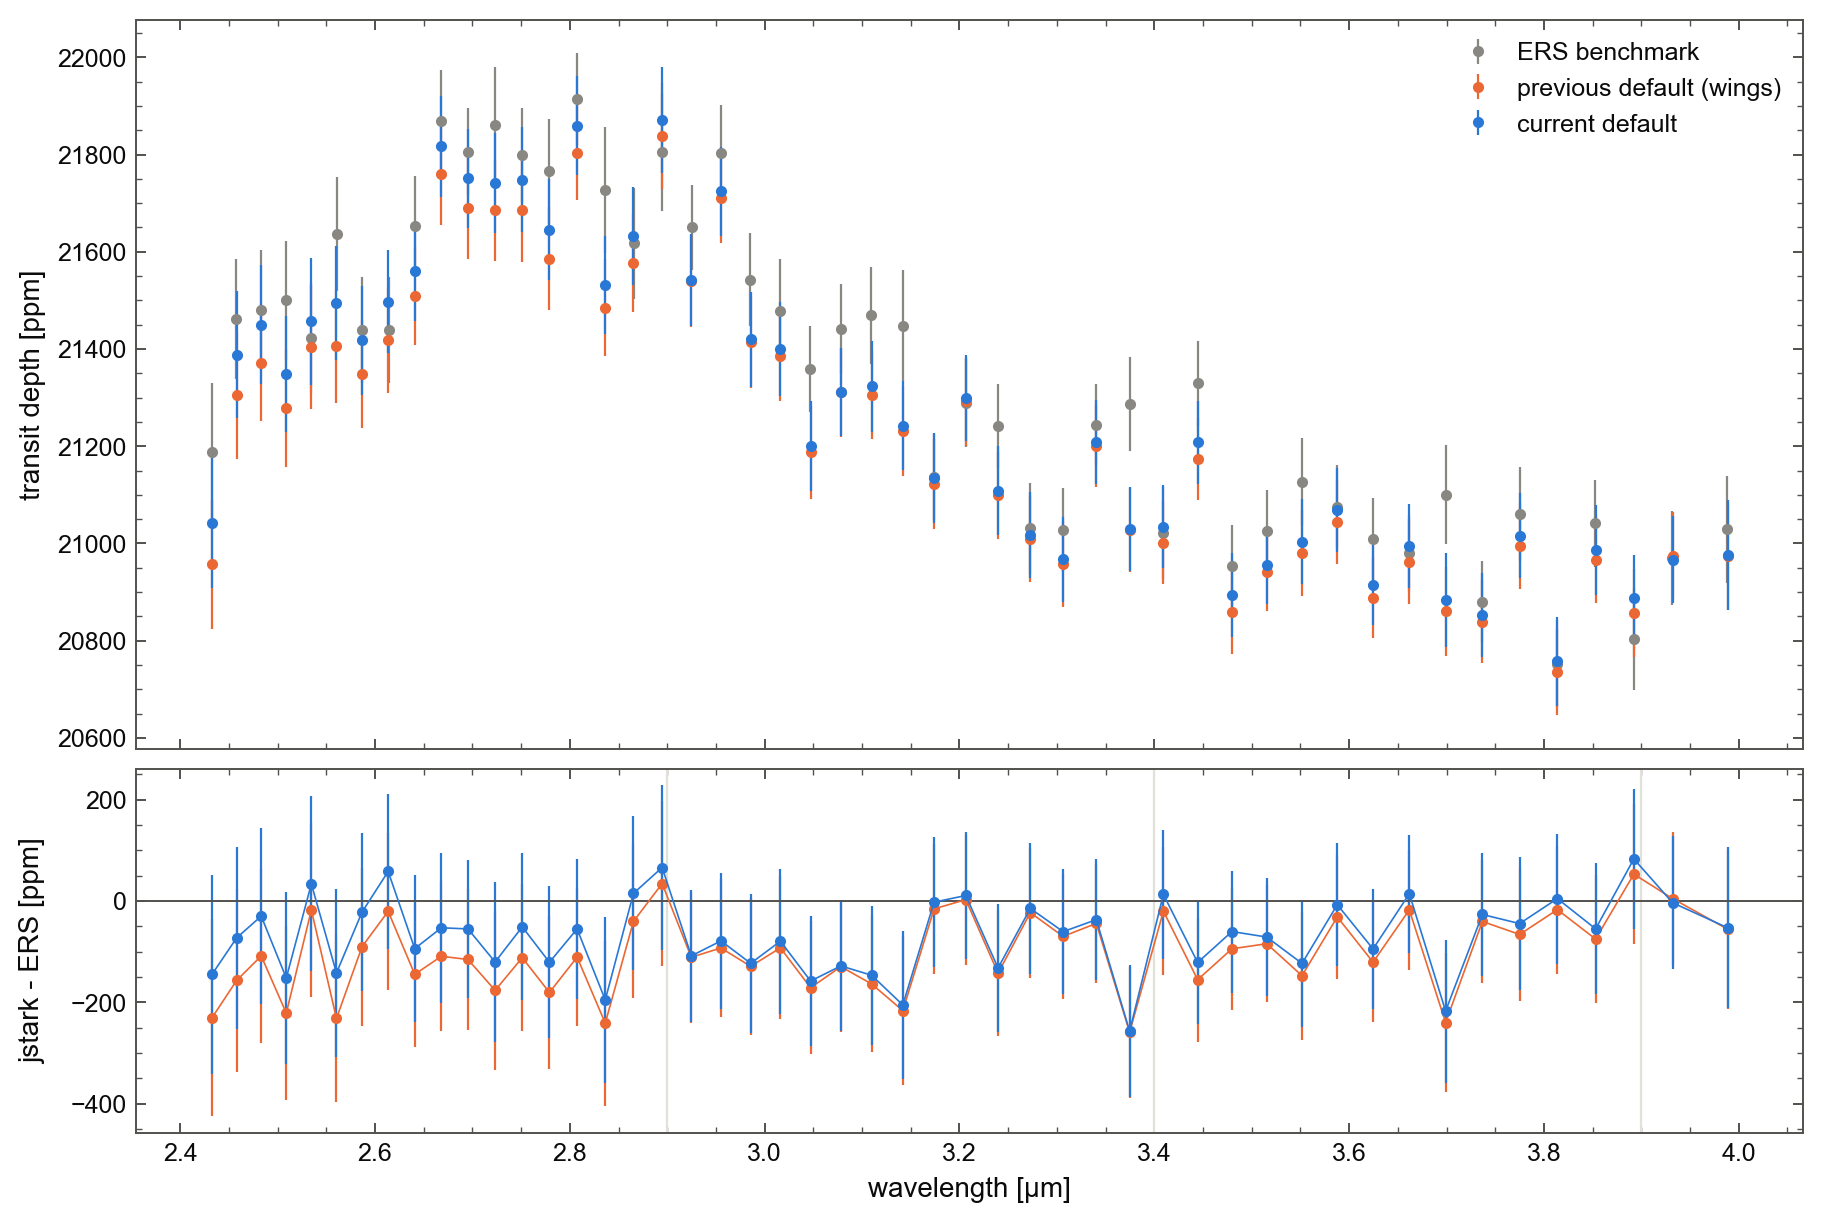

In [12]:
bench = Table.read(os.path.join(DATA, 'benchmark', 'ZENODO', '4_TRANSMISSION_SPECTRA',
                                'Fit_LimbDarkening', 'NIRCam_F322W2', 'R100.csv'))
spec_dir = os.path.join(NEW, 'fits', 'spec_nrc_none')
if RUN_FULL:
    pri = fit.channel_priors(fix=('P', 't0', 'a', 'b', 'ecc', 'omega'))
    pri = {k: v for k, v in pri.items() if not k.startswith(('p_p1', 'q1', 'q2'))}
    pri.update({'p_p1': ('uniform', [0.05, 0.25]),
                'q1_NRC': ('uniform', [0., 1.]), 'q2_NRC': ('uniform', [0., 1.])})
    edges = np.stack([bench['wave_low'], bench['wave_hig']], axis=1)
    sf = SpectroscopicFit({'NRC': lc}, priors=pri, out_folder=spec_dir, edges=edges,
                          linear=['time', 'phase4'])
    sf.run(nproc=6)

def depth(t):
    p = np.asarray(t['rp/rs'])
    return p ** 2 * 1e6, p * np.asarray(t['rp/rs_err_low'] + t['rp/rs_err_hih']) * 1e6

bd, be = depth(bench)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout='constrained',
                             gridspec_kw=dict(height_ratios=[2, 1]))
a1.errorbar(bench['wave'], bd, be, fmt='o', color='#898781', ms=3, elinewidth=0.8, label='ERS benchmark')
for name, d, col in (('previous default (wings)', OLD, 'C1'), ('current default', NEW, 'C0')):
    t = Spectrum.read(os.path.join(d, 'fits', 'spec_nrc_none', 'spectrum.ecsv'))
    b = np.asarray(t['bin'])
    dd = np.asarray(t['depth_p1_ppm'])
    ee = 0.5 * np.asarray(t['depth_p1_ppm_errp'] + t['depth_p1_ppm_errm'])
    diff = dd - bd[b]
    off = np.median(diff)
    print(f'{name:26s} median offset to ERS {off:5.0f} ppm, rms after it {np.std(diff - off):3.0f} ppm, '
          f'error ratio {np.median(ee / be[b]):.2f}')
    a1.errorbar(t['wave'], dd, ee, fmt='o', color=col, ms=3, elinewidth=0.8, label=name)
    a2.errorbar(t['wave'], diff, np.hypot(ee, be[b]), fmt='o-', lw=0.6, ms=3, elinewidth=0.8, color=col)
for x in (2.9, 3.4, 3.9):
    a2.axvline(x, color='#e1e0d9', lw=0.8)
a2.axhline(0, color='#52514e', lw=0.7)
a1.set_ylabel('transit depth [ppm]'); a1.legend()
a2.set_ylabel('jstark - ERS [ppm]'); a2.set_xlabel('wavelength [µm]')
fig.align_ylabels((a1, a2));

<div class="alert alert-info">

**How this compares with the published reductions**

The ERS benchmark spectrum is one reduction (Eureka!). Against the three
published NIRCam reductions of this transit (Ahrer et al. 2023), the
light-curve depths differ by (reduction − jstark, ppm):

| Reduction | previous default | current default |
| --- | --- | --- |
| Eureka! | +114 ± 9 | +56 ± 7 |
| tshirt | +51 ± 9 | **+1.5 ± 7.6** |
| HANSOLO | +27 ± 8 | −36 ± 8 |
| ERS benchmark | +110 ± 11 | +54 ± 8 |

With the current default jstark sits inside the spread of the published
reductions and agrees with tshirt, as on PRISM. The remaining −60 ppm
against the benchmark spectrum is the light curves (−54 ppm, i.e. Eureka!)
plus the orbit (−18 ppm).

**Common-mode correction.** Dividing each channel by the white-light
residuals of its amplifier (`SpectroscopicFit(common_mode=fit,
cm_mode='divide')`) changed the R = 100 depths by 3 ± 3 ppm and the errors
by 1%: per bin the shared noise (~200 ppm) is small next to each bin's own
(~1400 ppm per integration). It matters for a few wide bins, whose residuals
are otherwise red.

</div>

## 7. Summary

| Stage | NIRCam default | Evidence |
| --- | --- | --- |
| Stage 1 | `refpix` with side reference pixels, odd/even columns | standard for NIRCam |
| Stage 1 | `group_bkg`: `readout` model with a common mode across amplifiers, background pixels only | white light 1.5 × lower than no correction on HD 207496; −14 ppm dilution on WASP-39 b |
| Stage 1 | *not* `wing_frac` | lowest p2p without a transit, but 70 ppm dilution and β₃₂ 3.25 on the WASP-39 b transit |
| Extraction | `method='covariance'`, `cov_scale=500` | white light −10% (HD 207496) |
| Fitting | `phase4` regressor; amplifiers fitted separately in the white light | fast-frame-reset pattern; amplifiers cover different wavelengths |

The lesson for any new default: a lower point-to-point scatter on data
without a transit is necessary but not sufficient. A method that uses the
star's own light to estimate the noise must be checked on a transit or
eclipse, against a reduction that cannot dilute it.